# 06 – Foot Traffic Locations

Collects the places that bring people, especially young customers, past a potential
store location: rapid transit stations, high schools, and major post-secondary campuses.

**Data sources**
- **Stations:** TTC GTFS schedule data (City of Toronto Open Data)
- **High schools:** Statistics Canada Open Database of Educational Facilities (ODEF v2.1)
- **Major campuses:** hand-checked list in `data/manual/major_campuses.csv`

**Why not OpenStreetMap?** The public Overpass API now restricts automated requests,
so these layers use downloadable files instead. This also makes the project fully
reproducible without depending on a live server.

**Method**
- **Stations:** followed the GTFS chain (routes → trips → stop_times → stops) to find
  every stop on Lines 1, 2, 4, 5, and 6, then merged platform stops into one point per
  station. The TTC feed uses two naming conventions ("X Station - Southbound Platform"
  for the subway, "X Station Eastbound Platform" for LRT), so both are handled. Bloor
  and Yonge are merged into one interchange. Stations just outside the city (e.g.
  Vaughan Metropolitan Centre) are kept on purpose to avoid edge effects for
  hexagons near the boundary.
- **High schools:** facilities in ODEF flagged as upper secondary (ISCED level 3),
  selected with a spatial join to the city boundary.
- **Campuses:** ODEF's post-secondary records are incomplete (e.g. George Brown is
  missing, U of T appears only as an admissions office, TMU still listed as Ryerson),
  so the 12 largest campuses were added by hand with verified coordinates. Small
  private career colleges are excluded, since their student populations are too
  small to drive foot traffic.

**Results**
- 109 rapid transit stations
- 401 high schools
- 12 major campuses

**Limitations**
- ODEF data was collected 2019–2022, so recent school openings or closings may be missing.
- Campuses are treated equally regardless of enrolment size.

**Outputs:** `data/processed/stations.gpkg`, `high_schools.gpkg`, `campuses.gpkg`

In [21]:
import geopandas as gpd
import pandas as pd

# Load the city boundary and hexagons
city = gpd.read_file("../data/processed/city_boundary.gpkg")
hexes = gpd.read_file("../data/processed/hex_features.gpkg")


def to_points(gdf, label, dedupe_m):
    """Convert features to named points and remove duplicates
    (same name within dedupe_m metres)."""
    gdf = gdf.to_crs(epsg=32617)
    gdf = gdf[gdf["name"].notna()].copy()
    gdf["geometry"] = gdf.geometry.centroid
    gdf = gdf[["name", "geometry"]].reset_index(drop=True)

    buffers = gdf.copy()
    buffers["geometry"] = gdf.buffer(dedupe_m)
    near = gpd.sjoin(gdf, buffers, predicate="within")
    dupes = near[(near.index < near["index_right"]) & (near["name_left"] == near["name_right"])]
    gdf = gdf.drop(dupes["index_right"].unique()).reset_index(drop=True)

    gdf["category"] = label
    return gdf

In [22]:
GTFS = "../data/raw/ttc_gtfs/"

routes = pd.read_csv(GTFS + "routes.txt")

# route_type 1 = subway. Lines 5 and 6 (LRT) are route_type 0, like streetcars,
# so pick them out by line number instead.
rapid = routes[(routes["route_type"] == 1) |
               (routes["route_short_name"].astype(str).isin(["5", "6"]))]

rapid[["route_short_name", "route_long_name", "route_type"]]

,route_short_name,route_long_name,route_type
0,1,Line 1 (Yonge-University),1
66,2,Line 2 (Bloor - Danforth),1
127,4,Line 4 (Sheppard),1
144,5,Line 5 Eglinton,0
164,6,Line 6 Finch West,0


In [23]:
# GTFS links routes -> trips -> stop_times -> stops, so follow that chain
trips = pd.read_csv(GTFS + "trips.txt", usecols=["route_id", "trip_id"])
rapid_trip_ids = trips.loc[trips["route_id"].isin(rapid["route_id"]), "trip_id"]

stop_times = pd.read_csv(GTFS + "stop_times.txt", usecols=["trip_id", "stop_id"])
rapid_stop_ids = stop_times.loc[stop_times["trip_id"].isin(rapid_trip_ids), "stop_id"].unique()

stops = pd.read_csv(GTFS + "stops.txt")
rapid_stops = stops[stops["stop_id"].isin(rapid_stop_ids)].copy()
print("Platform stops:", len(rapid_stops))
rapid_stops["stop_name"].head(10)

Platform stops: 234


7995                Finch Station - Southbound Platform
7996    North York Centre Station - Southbound Platform
7997       Sheppard-Yonge Station - Southbound Platform
7998           York Mills Station - Southbound Platform
7999             Lawrence Station - Southbound Platform
8000             Eglinton Station - Southbound Platform
8001           Davisville Station - Southbound Platform
8002             St Clair Station - Southbound Platform
8003           Summerhill Station - Southbound Platform
8004             Rosedale Station - Southbound Platform
Name: stop_name, dtype: str

Stations: 109


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

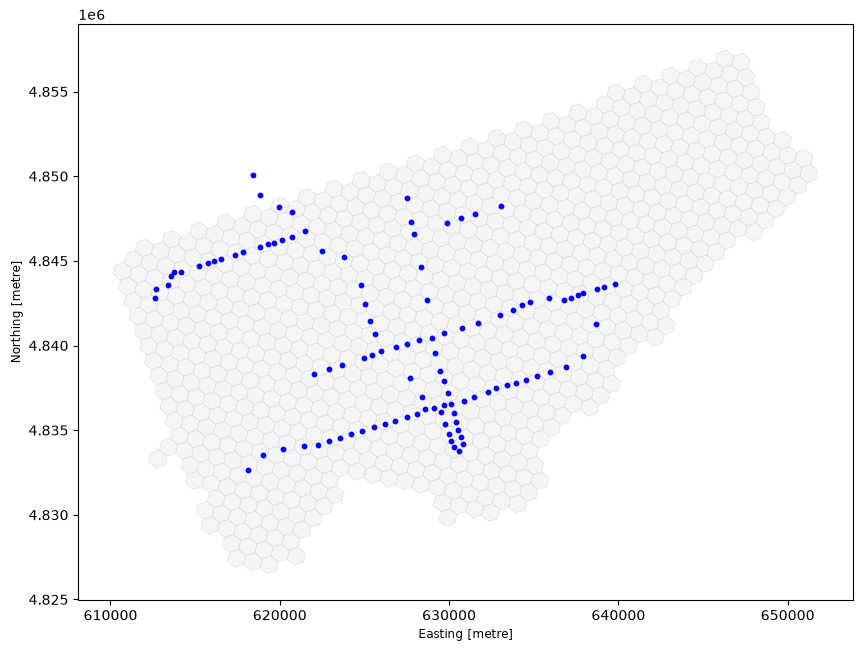

In [24]:
# Each station has several platform stops (e.g. "X Station - Northbound Platform"),
# so strip the platform part and average their locations
# Remove the platform part, with or without a dash:
#   "Finch Station - Southbound Platform" -> "Finch Station"
#   "Albion Station Eastbound Platform"   -> "Albion Station"
#   "Kennedy Station LRT Platform"        -> "Kennedy Station"
rapid_stops["station"] = (
    rapid_stops["stop_name"]
    .str.split(" - ").str[0]                     # subway: drop everything after " - "
    .str.replace(r"\s+(Northbound|Southbound|Eastbound|Westbound|LRT)\s+Platform$",
                 "", regex=True)                 # LRT: drop direction + "Platform"
    .str.strip()
)

rapid_stops["station"] = rapid_stops["station"].replace(
    {"Bloor Station": "Bloor-Yonge Station", "Yonge Station": "Bloor-Yonge Station"}
)

st = rapid_stops.groupby("station")[["stop_lat", "stop_lon"]].mean().reset_index()

stations = gpd.GeoDataFrame(
    {"name": st["station"], "category": "station"},
    geometry=gpd.points_from_xy(st["stop_lon"], st["stop_lat"]),
    crs="EPSG:4326",
).to_crs(epsg=32617)

print("Stations:", len(stations))
ax = hexes.plot(color="whitesmoke", edgecolor="lightgrey", linewidth=0.3, figsize=(10, 10))
stations.plot(ax=ax, color="blue", markersize=10)

In [25]:
for name in sorted(stations["name"]):
    print(name)

Aga Khan Park & Museum Station
Albion Station
Avenue Station
Bathurst Station
Bay Station
Bayview Station
Bessarion Station
Birchmount Station
Bloor-Yonge Station
Broadview Station
Caledonia Station
Castle Frank Station
Cedarvale Station
Chaplin Station
Chester Station
Christie Station
College Station
Coxwell Station
Davisville Station
Don Mills Station
Don Valley Station
Donlands Station
Downsview Park Station
Driftwood Station
Dufferin Station
Duncanwoods Station
Dundas West Station
Dupont Station
Eglinton Station
Emery Station
Fairbank Station
Finch Station
Finch West Station
Forest Hill Station
Glencairn Station
Golden Mile Station
Greenwood Station
Hakimi Lebovic Station
High Park Station
Highway 407 Station
Humber College Station
Ionview Station
Islington Station
Jane Station
Jane and Finch Station
Keele Station
Keelesdale Station
Kennedy Station
King Station
Kipling Station
Laird Station
Lansdowne Station
Lawrence Station
Lawrence West Station
Leaside Station
Leslie Station
Main

In [26]:
stations.to_file("../data/processed/stations.gpkg", driver="GPKG")
print("Saved", len(stations), "stations")

Saved 109 stations


In [27]:
odef = pd.read_csv("../data/raw/odef/ODEF_v2_1.csv", encoding="latin-1", low_memory=False)
print("Facilities in Canada:", len(odef))
print(odef.columns.tolist())
odef.head()

Facilities in Canada: 18982
['Index', 'Source_ID', 'Facility_Name', 'Facility_Type', 'Authority_Name', 'ISCED010', 'ISCED020', 'ISCED1', 'ISCED2', 'ISCED3', 'ISCED4Plus', 'OLMS_Status', 'Full_Addr', 'Unit', 'Street_No', 'Street_Name', 'City', 'Prov_Terr', 'Postal_Code', 'PRUID', 'CSDNAME', 'CSDUID', 'Longitude', 'Latitude', 'Geo_Source', 'Provider', 'CMANAME', 'CMAUID']


,Index,Source_ID,Facility_Name,Facility_Type,Authority_Name,ISCED010,ISCED020,ISCED1,ISCED2,ISCED3,...,Postal_Code,PRUID,CSDNAME,CSDUID,Longitude,Latitude,Geo_Source,Provider,CMANAME,CMAUID
0,22d419f97afba4e3e46d,1466,École Joseph-Moreau,Francophone,The Greater North Central Francophone Educatio...,..,0,0,1,0,...,T6E1E8,48,Edmonton,4811061,-113.4812942,53.51064275,Nominatim,Province of Alberta,Edmonton,835
1,bb5664826c68c18f0c90,1467,École Alexandre-Taché,Francophone,The Greater North Central Francophone Educatio...,..,0,0,1,1,...,T8N5S5,48,St. Albert,4811062,-113.6250664,53.65889362,AGOL,Province of Alberta,Edmonton,835
2,3b6e0d66ab951460be66,1786,École Saint-Vital,Francophone,The Greater North Central Francophone Educatio...,..,1,1,1,0,...,T4X1V8,48,Beaumont,4811013,-113.4219248,53.3385921,Nominatim,Province of Alberta,Edmonton,835
3,77cd6b9f5ae674d9f400,2125,École Michaëlle-Jean,Francophone,The Greater North Central Francophone Educatio...,..,0,1,1,1,...,T6A3P8,48,Edmonton,4811061,-113.456566,53.53972827,AGOL,Province of Alberta,Edmonton,835
4,a54b02c277d8a7c42b18,1228,École Mont Carmel,Public,DSF-S,..,1,1,1,0,...,E4S2H2,13,Saint Mary,1308006,-64.82560578,46.41469453,Source,Province of New Brunswick,...,...


In [28]:
# StatCan uses ".." for missing values, so convert to numbers and drop those
for col in ["Longitude", "Latitude"]:
    odef[col] = pd.to_numeric(odef[col], errors="coerce")

missing = odef[["Longitude", "Latitude"]].isna().any(axis=1)
print("Facilities with no coordinates (dropped):", missing.sum())
odef = odef[~missing]

odef_gdf = gpd.GeoDataFrame(
    odef,
    geometry=gpd.points_from_xy(odef["Longitude"], odef["Latitude"]),
    crs="EPSG:4326",
).to_crs(epsg=32617)

odef_city = gpd.sjoin(odef_gdf, city[["geometry"]], predicate="within").drop(columns="index_right")

print("Facilities in Toronto:", len(odef_city))
print(odef_city["Facility_Type"].value_counts())

odef_city.filter(like="ISCED").apply(pd.Series.value_counts)

Facilities with no coordinates (dropped): 3382
Facilities in Toronto: 1298
Facility_Type
Public                      602
Private                     372
Catholic                    223
Private Institution          90
Technical and Vocational      6
University                    3
Hospital                      1
Junior College                1
Name: count, dtype: int64


,ISCED010,ISCED020,ISCED1,ISCED2,ISCED3,ISCED4Plus
..,100,100,100,100,100,1198.0
0,613,610,358,271,797,NaN
1,585,588,840,927,401,100.0


In [29]:
raw = pd.read_csv("../data/raw/odef/ODEF_v2_1.csv", encoding="latin-1", low_memory=False)
no_coords = pd.to_numeric(raw["Longitude"], errors="coerce").isna()
print("Toronto facilities with no coordinates:", (no_coords & (raw["CSDNAME"] == "Toronto")).sum())

Toronto facilities with no coordinates: 0


In [30]:
isced3 = pd.to_numeric(odef_city["ISCED3"], errors="coerce") == 1
high_schools = odef_city[isced3].rename(columns={"Facility_Name": "name"})
high_schools = to_points(high_schools, "high_school", dedupe_m=100)
print("High schools:", len(high_schools))

High schools: 401


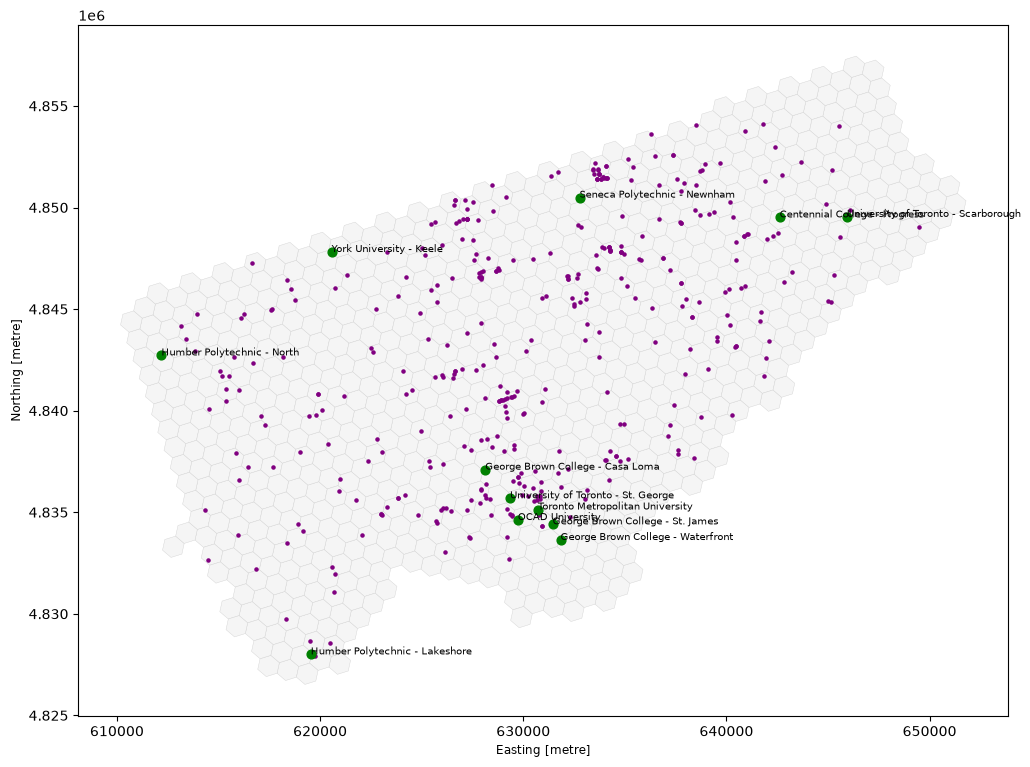

In [31]:
camp = pd.read_csv("../data/manual/major_campuses.csv")
campuses = gpd.GeoDataFrame(
    {"name": camp["name"], "category": "campus"},
    geometry=gpd.points_from_xy(camp["lon"], camp["lat"]),
    crs="EPSG:4326",
).to_crs(epsg=32617)

ax = hexes.plot(color="whitesmoke", edgecolor="lightgrey", linewidth=0.3, figsize=(12, 12))
high_schools.plot(ax=ax, color="purple", markersize=5)
campuses.plot(ax=ax, color="green", markersize=40)
for _, row in campuses.iterrows():
    ax.annotate(row["name"], (row.geometry.x, row.geometry.y), fontsize=7)

In [32]:
high_schools.to_file("../data/processed/high_schools.gpkg", driver="GPKG")
campuses.to_file("../data/processed/campuses.gpkg", driver="GPKG")
print("Saved")

Saved
